# Health Study — Data Analysis

## 1. Data Overview and Quality Assessment

Syftet med den första delen av analysen är att undersöka datasetets struktur och datakvalitet innan den statistiska analysen påbörjas.

Vi kontrollerar datatyper, saknade värden, dubbletter samt möjliga avvikande eller orimliga värden.

In [1]:
import sys
from pathlib import Path

# Lägg till projektets rotmapp för att kunna importera moduler
sys.path.insert(0, str(Path.cwd().parent))

from src.data_processing import load_data

df = load_data()

# Visa datasetets storlek och de första raderna
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (800, 9)


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


In [2]:
# Visa kolumnernas datatyper och antal värden
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


In [3]:
# Kontrollera saknade värden
print("Missing values:")
print(df.isna().sum())

Missing values:
id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64


In [4]:
# Kontrollera dubbletter
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["id"].duplicated().sum())


Duplicate rows: 0
Duplicate IDs: 0


In [5]:
# Välj kolumner för numerisk analys
numeric_columns = [
    "age", "weight", "height",
    "systolic_bp", "cholesterol"
]

# Visa beskrivande statistik
display(df[numeric_columns].describe())
      

,age,weight,height,systolic_bp,cholesterol
count,800.000000,800.000000,800.000000,800.000000,800.000000
mean,49.426250,73.413000,171.849250,149.178625,4.929150
std,14.501118,13.685059,9.804259,12.793360,0.848413
min,18.000000,33.700000,144.400000,106.800000,2.500000
25%,39.000000,64.800000,164.775000,140.900000,4.327500
50%,50.000000,73.200000,171.350000,149.400000,4.970000
75%,59.000000,82.600000,178.925000,157.600000,5.482500
max,90.000000,114.400000,200.400000,185.900000,7.880000


In [6]:
# Kontrollera fördelningen av kategoriska värden
for column in ["sex", "smoker", "disease"]:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))
      


sex:
sex
F    403
M    397
Name: count, dtype: int64

smoker:
smoker
No     587
Yes    213
Name: count, dtype: int64

disease:
disease
0    753
1     47
Name: count, dtype: int64


### Data Overview and Quality Assessment — Conclusion

Datasetet innehåller **800 observationer och 9 kolumner**:

- `id` – deltagarens ID
- `age` – ålder
- `sex` – kön
- `height` – längd
- `weight` – vikt
- `systolic_bp` – systoliskt blodtryck
- `cholesterol` – kolesterolnivå
- `smoker` – rökvanor
- `disease` – förekomst av sjukdom

**Datakvalitet:** Inga saknade värden eller dubbletter hittades. Datatyperna är korrekta och inga uppenbart orimliga värden identifierades.

**Slutsats:** Datasetet bedöms vara lämpligt för fortsatt analys utan ytterligare datarensning i detta steg.


## 2. Beskrivande analys

I detta avsnitt undersöker vi deltagarnas egenskaper med hjälp av beskrivande statistik och visualiseringar.

### 2.1 Descriptive Statistics

Vi beräknar medelvärde, median, minimum och maximum för ålder, vikt, längd, systoliskt blodtryck och kolesterolnivå.


In [7]:
from src.statistics import calculate_descriptive_stats, display_descriptive_stats

stats = calculate_descriptive_stats(df)
display_descriptive_stats(stats)



Ålder (år)
------------------------------
Medelvärde: 49.43
Median:     50.00
Minimum:    18.00
Maximum:    90.00

Vikt (kg)
------------------------------
Medelvärde: 73.41
Median:     73.20
Minimum:    33.70
Maximum:    114.40

Längd (cm)
------------------------------
Medelvärde: 171.85
Median:     171.35
Minimum:    144.40
Maximum:    200.40

Systoliskt blodtryck (mmHg)
------------------------------
Medelvärde: 149.18
Median:     149.40
Minimum:    106.80
Maximum:    185.90

Kolesterolnivå
------------------------------
Medelvärde: 4.93
Median:     4.97
Minimum:    2.50
Maximum:    7.88


### 2.2 Data Visualization

För att komplettera den beskrivande statistiken visualiserar vi data med hjälp av olika diagram. Detta gör det lättare att se fördelningar, skillnader mellan grupper och eventuella avvikande värden.

Vi undersöker fördelningen av systoliskt blodtryck, jämför vikt mellan kvinnor och män samt visar andelen rökare bland deltagarna.

#### 2.2.1 Systolic Blood Pressure

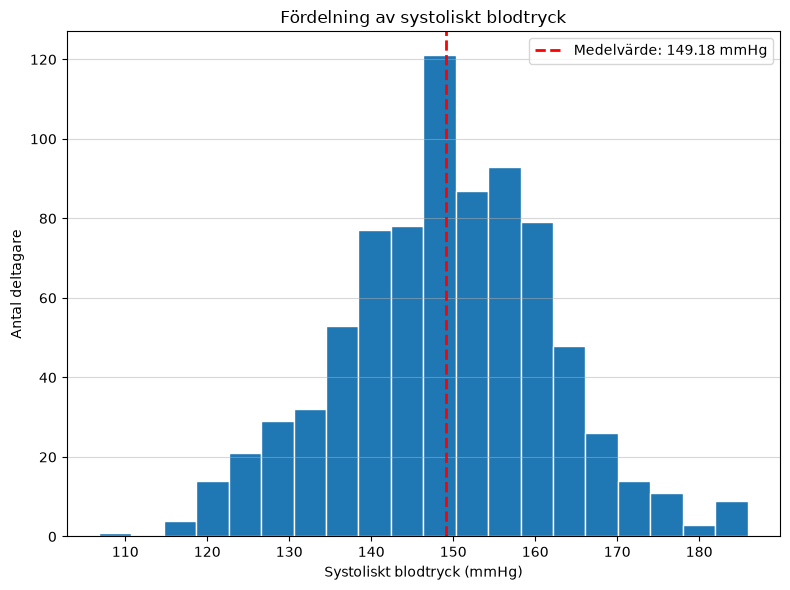

In [8]:
import matplotlib.pyplot as plt
from src.viz import plot_blood_pressure, plot_weight_by_sex, plot_smoking_distribution

fig, ax = plot_blood_pressure(df)
plt.show()


#### Fördelning av systoliskt blodtryck – analys

Histogrammet visar hur det systoliska blodtrycket är fördelat bland studiens deltagare. Varje stapel visar antalet deltagare inom ett visst blodtrycksintervall. Den röda streckade linjen markerar medelvärdet, som är cirka 149,18 mmHg.

#### 2.2.2 Weight Distribution by Sex

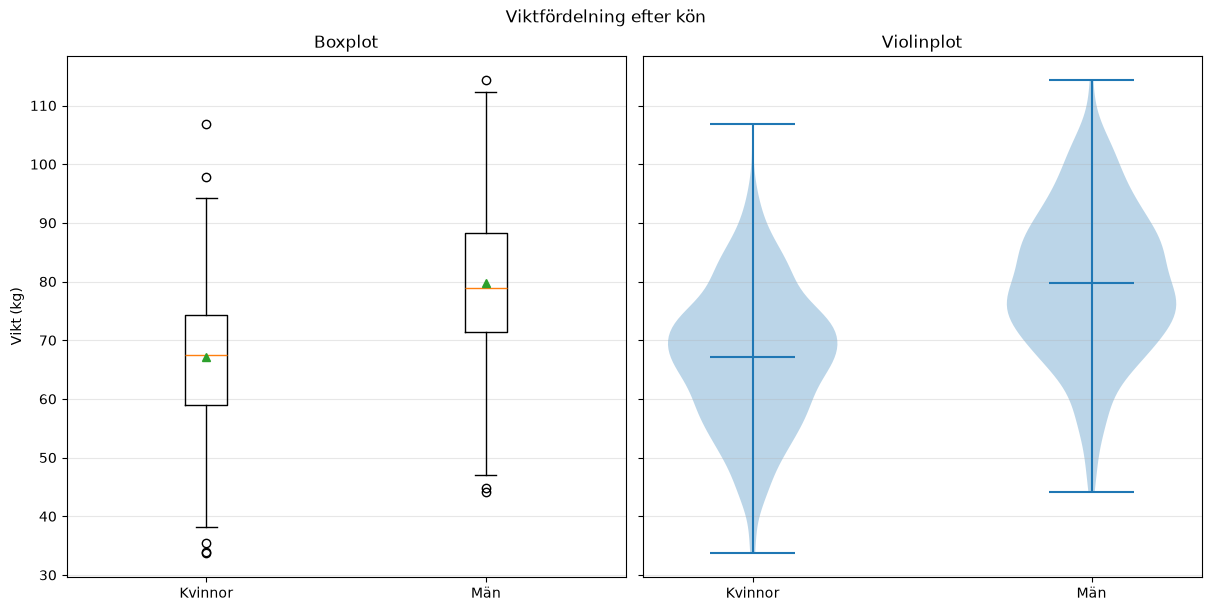

In [9]:

fig, axes = plot_weight_by_sex(df)
plt.show()

#### Viktfördelning efter kön – analys

Diagrammen visar att män generellt väger mer än kvinnor i detta dataset. Medianvikten är cirka 79 kg för män och 68 kg för kvinnor, vilket motsvarar en skillnad på ungefär 11 kg.

Boxploten visar också att viktvariationen är något större bland män och att det finns några avvikande värden i båda grupperna. Violinploten visar att de vanligaste viktvärdena ligger högre för män än för kvinnor.

Sammantaget visar diagrammen en tydlig skillnad i viktfördelningen mellan könen.

#### 2.2.3 Smoking Distribution

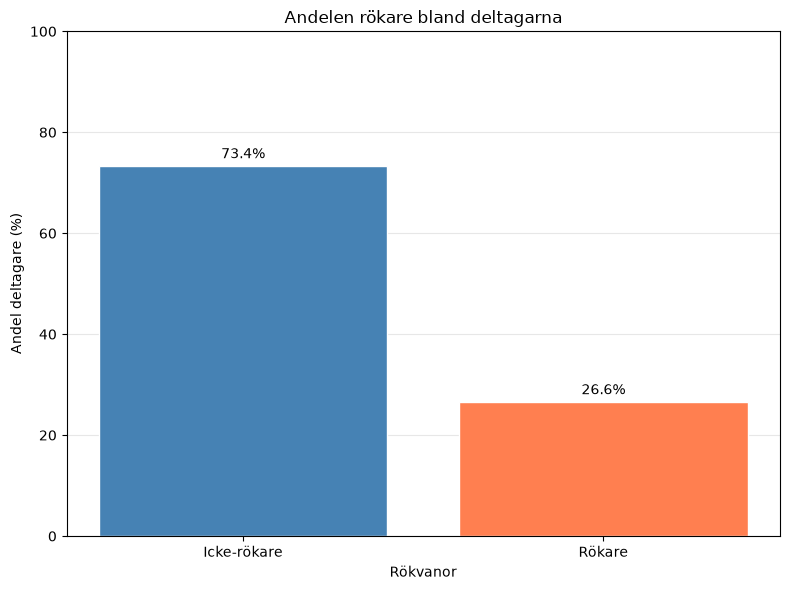

In [10]:
fig, ax = plot_smoking_distribution(df)
plt.show()

#### Smoking Distribution – Analysis

Diagrammet visar att majoriteten av deltagarna är icke-rökare (73,4 %), medan 26,6 % är rökare. Andelen icke-rökare är alltså betydligt större.

### 2.3 Conclusion

Den beskrivande analysen visar att det finns variationer i deltagarnas ålder, vikt, längd, blodtryck och kolesterolnivå. Viktfördelningen skiljer sig mellan kvinnor och män, där män generellt väger mer. Dessutom är majoriteten av deltagarna icke-rökare.

Diagrammen kompletterar de statistiska beräkningarna och ger en tydligare bild av datasetet.

## 3. Simulering av sjukdomsförekomst

I detta avsnitt simulerar vi sjukdomsförekomsten hos 1000 personer utifrån andelen sjuka i det ursprungliga datasetet.

Vi använder en binomialfördelning och ett fast slumpfrö (`seed=89`) för att göra simuleringen reproducerbar. Därefter jämför vi den simulerade andelen sjuka med den observerade andelen i datasetet.

In [12]:
from src.statistics import simulate_disease

original_rate, simulated_count, simulated_rate = simulate_disease(df)
difference = (simulated_rate - original_rate) * 100

print(f"Ursprunglig andel sjuka: {original_rate:.3%}")
print(f"Antal sjuka i simuleringen: {simulated_count}")
print(f"Simulerad andel sjuka: {simulated_rate:.2%}")
print(f"Skillnad: {difference:.3f} procentenheter")

Ursprunglig andel sjuka: 5.875%
Antal sjuka i simuleringen: 58
Simulerad andel sjuka: 5.80%
Skillnad: -0.075 procentenheter


### 3.1 Jämförelse och slutsats

I det ursprungliga datasetet är andelen sjuka 5,875 %, medan den simulerade andelen är 5,80 %. Skillnaden är endast 0,075 procentenheter.

Resultaten ligger mycket nära varandra. Den lilla skillnaden beror på slumpmässig variation.